# NeuroGuard
### When better MRI recall creates more false alarms

**AI + Health · Solo submission · Veritas AI International High School Hackathon 2026**

**Pitch:** Compare abnormal-region predictions on compatible brain MRI slices and
see the cost of improving recall. Intended user: a radiologist or imaging researcher
exploring a potential review aid. Input: an original LGG three-channel TIFF slice.
Output: a FLAIR image, predicted binary mask and coloured overlay.

**This project is a prototype and is not medical advice.** Highlighted pixels are
model predictions, not confirmed abnormalities.

**Research question:** I asked whether recall-oriented Tversky loss could improve
detection of small annotated abnormalities compared with BCE, without an
unacceptable rise in false positives.

**Finding:** Only partially. Recall improved, but false positives were severe.
Overall Dice superiority is not firmly established.

[Official write-up — README](../README.md) · [App instructions](../docs/demo.md) ·
[Full protocol](../docs/evaluation-protocol.md) · [Sources](../docs/sources-and-licensing.md)

This notebook is a lightweight **readout of completed experiments**, not a training
or evaluation pipeline. Its executed cells load a curated saved aggregate extract
and format tables/plots. No models, MRI files or private Drive access are needed.
The four original research notebooks remain unchanged. No metrics are newly estimated here.

## Why this problem needs more than pixel accuracy

A prospective review aid must highlight annotated regions without overwhelming a
reader with false alarms. Missing an annotated region and highlighting unannotated
background are different failures. I evaluate both; neither overlap scores nor
one successful overlay establishes clinical usefulness.

Most pixels are background. An always-empty mask is therefore a necessary baseline:
it can have impressive pixel accuracy while detecting none of the annotated foreground.
My contribution is a controlled loss-function comparison, patient-level evaluation,
size analysis and explicit failure analysis, rather than a new U-Net architecture.

## Dataset and patient separation

[Mateusz Buda's LGG MRI Segmentation dataset](https://www.kaggle.com/datasets/mateuszbuda/lgg-mri-segmentation),
version 2, contains **110 patients and 3,929 paired images/masks**, with 256 × 256
three-channel TIFF images. Stored channels are pre-contrast / FLAIR / post-contrast,
including the dataset's documented substitutions for missing sequences. Channel 1
is used for grayscale display; the model receives all three channels.

The annotation target is a FLAIR abnormality region, not an independently established
diagnosis. Public Kaggle metadata lists **CC BY-NC-SA 4.0**; see the
[attribution and publication boundaries](../docs/sources-and-licensing.md).

| Frozen split | Patients | Slices |
|---|---:|---:|
| Training | 77 | 2,719 |
| Validation | 16 | 621 |
| Test | 17 | 589 (230 positive; 359 empty masks) |

I used a frozen patient-disjoint split: each patient's slices appear in **one split only**. Adjacent slices from a patient
are correlated; splitting slices randomly would make leakage likely. Pairing,
dimensions, binary masks and exact duplicate integrity were audited before the
split was frozen. Exact hashes cannot exclude all near-duplicates. The original
manifest is preserved; this notebook does not reconstruct or change it.

In [1]:
import json
from pathlib import Path
from IPython.display import display, Markdown

root = Path.cwd()
if not (root / "results/final-summary.json").is_file():
    root = root.parent
saved = json.loads((root / "results/final-summary.json").read_text(encoding="utf-8"))
metrics = saved["metrics"]
def table(headers, rows):
    text = "| " + " | ".join(headers) + " |\n"
    text += "|" + "|".join(["---"] * len(headers)) + "|\n"
    text += "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown(text))
print("Completed Phase 5 source:", saved["provenance"]["evaluation_source_commit"])
print("Frozen manifest:", saved["provenance"]["manifest_sha256"])
print("Readout only: no training, inference, threshold search or metric recomputation.")

Completed Phase 5 source: d26811abb564680075030d7970633b4e681a98d4
Frozen manifest: 7514044281736b609e9d1c09c342a3f2514d0a2ca4dea9c4ce0d466cd86fe493
Readout only: no training, inference, threshold search or metric recomputation.


## Three approaches, one controlled comparison

I designed the comparison to hold architecture, preprocessing and selection
rules fixed while changing the loss function.

**Always empty:** no learned parameters; predicts background for every pixel.

**BCE U-Net:** a small encoder–decoder network. The contracting path learns features
at progressively coarser scales; the expanding path restores resolution. Skip
connections carry spatial detail across matching scales. Four downsamplings use
widths 16/32/64/128 with a 256-channel bottleneck; convolution, BatchNorm and ReLU
blocks lead to one foreground logit per pixel. Total: **1,942,577 parameters**.
BCEWithLogitsLoss scores pixel labels with a stable sigmoid/cross-entropy calculation.

**Tversky U-Net:** identical architecture and initialisation, a different loss:

$$L=1-\frac{TP+\epsilon}{TP+0.3FP+0.7FN+\epsilon},\qquad \epsilon=10^{-6}.$$

Here TP/FP/FN are soft sums of sigmoid probabilities and binary targets, computed
**per slice and then averaged over the batch**, including empty masks. A larger
FN coefficient motivates the recall hypothesis. It is not a guarantee: smoothing
and this reduction can produce extremely weak false-positive gradients on empty
masks, a limitation documented with synthetic checks before the real Tversky run.
No hybrid objective or outcome-driven loss changes were introduced.

Both arms use float32, seed 42, Adam (learning rate .001, no weight decay), batch 16,
maximum 30 epochs and patience 7. Checkpoints maximise validation patient-macro
positive Dice at threshold .5; earliest ties win. BCE completed 25 epochs (best 18),
Tversky 30 (best 23): equal rules and budgets, not an assertion of identical epochs.
No pretrained weights were used. [Full model](../src/model.py),
[losses](../src/losses.py), [BCE config](../configs/bce.json),
[Tversky config](../configs/tversky.json).

## Frozen experimental design

- Original three-channel preprocessing: centred square padding/resize to 256,
  per-image/channel nonzero-pixel z-score; constant channels become zero. No
  validation/test-fitted statistics. Training-only joint horizontal flips and
  ±10° rotations use bilinear image and nearest-neighbour mask interpolation.
- Validation selects thresholds using the same .10–.90 grid for both models.
  Maximise primary Dice subject to ≤10% empty-mask FP rate, with frozen tie-breaks.
  If none qualifies, retain .5 and explicitly mark the constraint unmet.
- BCE selected .8 and met the validation FP criterion. Tversky failed it at all
  tested points and retained .5 as a **constraint-failure fallback**.
- Test protocol, checkpoint hashes and deterministic example selection were
  locked before the one completed held-out evaluation. No test threshold tuning.
- Small/medium/large categories use training-positive-slice area tertiles, frozen
  before test prediction. These describe 2D annotation burden, not 3D tumour volume.
- Patient-macro positive Dice/recall/precision average eligible slices within each
  patient, then patients equally. Empty slices are excluded from these metrics.
  Positive ground truth with empty prediction has zero Dice/recall/precision.
- Empty-mask FP slice rate is **empty-mask slices with any predicted foreground /
  all empty-mask slices**, a slice-micro rate. Such slices do not prove a patient
  is clinically healthy. Pooled all-slice Dice instead pools pixel counts and
  includes empty-slice false positives; it is a different measure.

The 10% absolute FP limit and ≤5 percentage-point increase over BCE are **research
criteria, not clinical safety standards**. See the [frozen protocol](../docs/evaluation-protocol.md).

In [2]:
rows = []
for name in ("small", "medium", "large"):
    group = metrics["always_empty"]["size_groups"][name]
    rows.append([name.title(), group["patients"], group["slices"]])
table(["Test annotation group", "Eligible patients", "Slices"], rows)
q1, q2 = saved["size_cutoffs"]
print(f"Training-derived area fractions: small ≤ {q1:.12f}; medium ≤ {q2:.12f}; large above.")
print("Counts are slice-level annotation groups; the same patient can contribute to multiple groups.")

| Test annotation group | Eligible patients | Slices |
|---|---|---|
| Small | 17 | 88 |
| Medium | 15 | 85 |
| Large | 8 | 57 |

Training-derived area fractions: small ≤ 0.016067504883; medium ≤ 0.037246704102; large above.
Counts are slice-level annotation groups; the same patient can contribute to multiple groups.


## Final held-out results

I report the completed held-out evaluation from saved JSON aggregates, with
source-file SHA256 values retained for provenance. This notebook formats those
results; it does not generate new test predictions or estimates.

### Common threshold 0.5

This isolates the loss comparison at a common decision rule. Dice, recall and
precision are patient-macro on positive-mask slices; small metrics use the same
two-stage aggregation restricted to the small group.

In [3]:
labels = [("Always empty", "always_empty"), ("BCE · 0.5", "bce_default"),
          ("Tversky · 0.5 (fallback)", "tversky_default")]
def metric_row(label, key):
    r = metrics[key]
    p, small = r["positive_patient_macro"], r["size_groups"]["small"]
    return [label, f"{p['dice']:.5f}", f"{p['recall']:.5f}", f"{p['precision']:.5f}",
            f"{small['dice']:.5f}", f"{small['recall']:.5f}",
            f"{100*r['empty']['false_positive_rate']:.2f}%",
            f"{r['pooled_all_slices']['dice']:.5f}"]
table(["Approach", "Positive Dice", "Recall", "Precision", "Small Dice", "Small recall", "Empty FP", "Pooled Dice"],
      [metric_row(label, key) for label, key in labels])
print(f"Always-empty pooled pixel accuracy: {100*metrics['always_empty']['pooled_all_slices']['pixel_accuracy']:.2f}%.")
print("Despite high background accuracy, it finds none of the annotated foreground.")

| Approach | Positive Dice | Recall | Precision | Small Dice | Small recall | Empty FP | Pooled Dice |
|---|---|---|---|---|---|---|---|
| Always empty | 0.00000 | 0.00000 | 0.00000 | 0.00000 | 0.00000 | 0.00% | 0.00000 |
| BCE · 0.5 | 0.76726 | 0.79521 | 0.77823 | 0.60471 | 0.67074 | 27.02% | 0.81326 |
| Tversky · 0.5 (fallback) | 0.77690 | 0.86362 | 0.75231 | 0.63995 | 0.78865 | 85.79% | 0.63846 |

Always-empty pooled pixel accuracy: 98.97%.
Despite high background accuracy, it finds none of the annotated foreground.


### Validation-selected / fallback points

These points were fixed using validation, not the test cohort. Tversky .5 is
identical to its common-threshold prediction, so it is not a fourth trained model.
BCE .8 had validation FP 9.47%, but test FP **14.48%**: its validation constraint
did not generalise fully. Tversky test FP is **85.79%**, far above the 10% criterion.

In [4]:
table(["Operating point", "Positive Dice", "Recall", "Precision", "Small Dice", "Small recall", "Empty FP", "Pooled Dice"],
      [metric_row("BCE · 0.8 (validation-selected)", "bce_selected"),
       metric_row("Tversky · 0.5 (failed constraint; fallback)", "tversky_selected")])

| Operating point | Positive Dice | Recall | Precision | Small Dice | Small recall | Empty FP | Pooled Dice |
|---|---|---|---|---|---|---|---|
| BCE · 0.8 (validation-selected) | 0.66951 | 0.60194 | 0.84968 | 0.47007 | 0.40715 | 14.48% | 0.79931 |
| Tversky · 0.5 (failed constraint; fallback) | 0.77690 | 0.86362 | 0.75231 | 0.63995 | 0.78865 | 85.79% | 0.63846 |

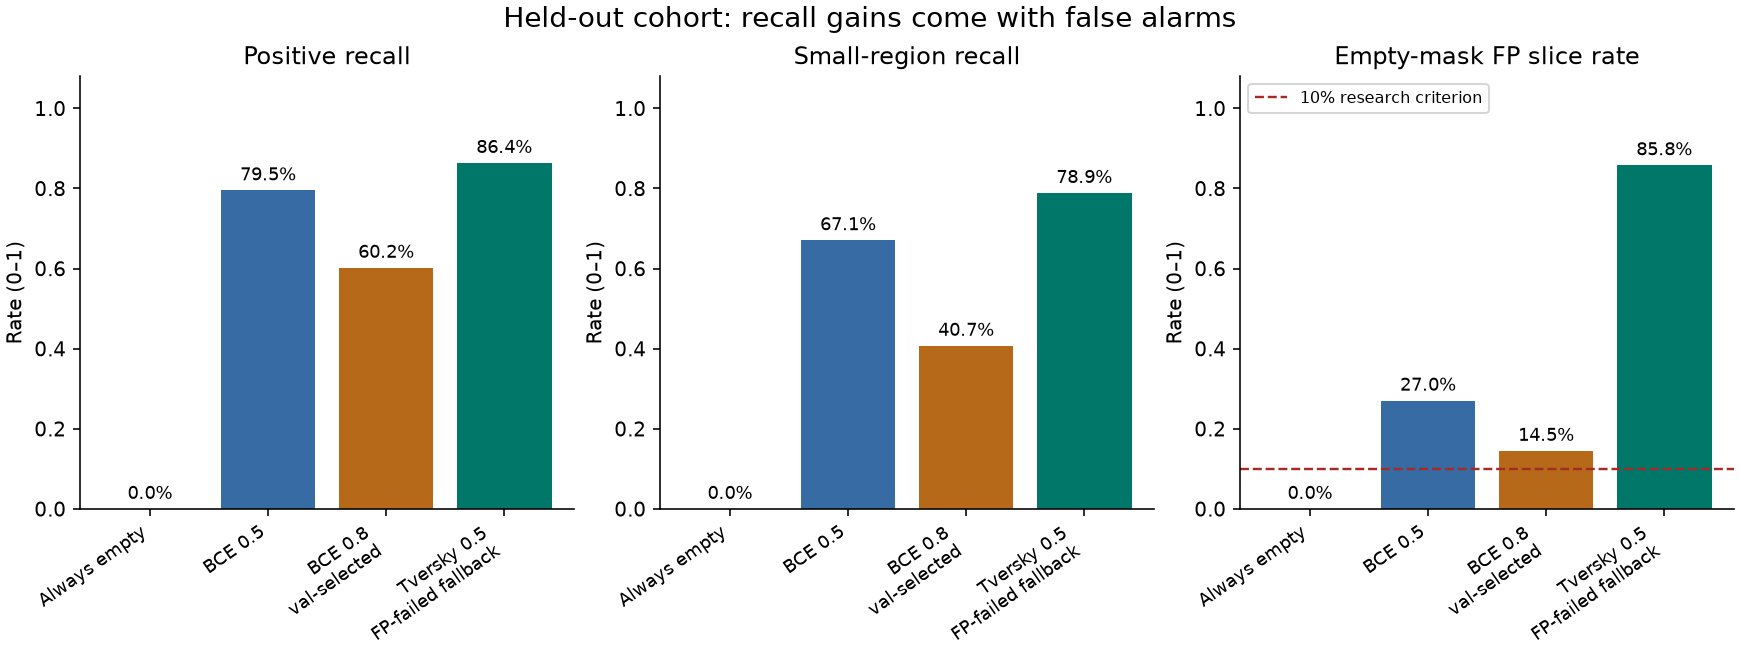

Presentation-only plot of saved metrics; no predictions or new performance estimates.


In [5]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image
from io import BytesIO

points = ["always_empty", "bce_default", "bce_selected", "tversky_default"]
names = ["Always empty", "BCE 0.5", "BCE 0.8\nval-selected", "Tversky 0.5\nFP-failed fallback"]
colours = ["#777777", "#376ba4", "#b66a19", "#007769"]
series = [([metrics[k]["positive_patient_macro"]["recall"] for k in points], "Positive recall"),
          ([metrics[k]["size_groups"]["small"]["recall"] for k in points], "Small-region recall"),
          ([metrics[k]["empty"]["false_positive_rate"] for k in points], "Empty-mask FP slice rate")]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), layout="constrained")
for ax, (values, title) in zip(axes, series):
    ax.bar(range(4), values, color=colours)
    ax.set(title=title, ylim=(0, 1.08), ylabel="Rate (0–1)")
    ax.set_xticks(range(4), names, rotation=35, ha="right", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    for x, value in enumerate(values):
        ax.text(x, value+.025, f"{100*value:.1f}%", ha="center", fontsize=9)
axes[-1].axhline(.1, color="#a62b27", linestyle="--", linewidth=1.2, label="10% research criterion")
axes[-1].legend(fontsize=8, loc="upper left")
fig.suptitle("Held-out cohort: recall gains come with false alarms", fontsize=14)
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=145)
display(Image(data=buffer.getvalue()))
plt.close(fig)
print("Presentation-only plot of saved metrics; no predictions or new performance estimates.")

## Uncertainty: one small patient cohort

The original evaluation used **1,000 paired patient-bootstrap replicates, seed 42,
95% percentile intervals**. Patients, not individual correlated slices, were
resampled. Differences below are **Tversky minus BCE at 0.5**, in percentage points.
The intervals are read from the saved report; no bootstrap is rerun here.

In [6]:
rows = []
for key, label in [("positive_recall","Positive recall"), ("small_recall","Small-region recall"),
                   ("positive_dice","Positive Dice"), ("small_dice","Small-region Dice")]:
    result = saved["bootstrap"]["common_threshold"][key]
    lo, hi = result["ci"]
    rows.append([label, f"{100*result['difference']:+.2f}",
                 f"{100*lo:+.2f} to {100*hi:+.2f}",
                 result["eligible_patients"], result["defined_replicates"], result["undefined_replicates"]])
table(["Metric", "Difference (pp)", "95% interval (pp)", "Eligible patients", "Defined replicates", "Undefined"], rows)

| Metric | Difference (pp) | 95% interval (pp) | Eligible patients | Defined replicates | Undefined |
|---|---|---|---|---|---|
| Positive recall | +6.84 | +3.41 to +10.47 | 17 | 1000 | 0 |
| Small-region recall | +11.79 | +4.95 to +19.97 | 17 | 1000 | 0 |
| Positive Dice | +0.96 | -1.96 to +3.87 | 17 | 1000 | 0 |
| Small-region Dice | +3.52 | -2.35 to +8.86 | 17 | 1000 | 0 |

Recall intervals favour Tversky within this cohort, while the positive/small
Dice difference intervals span zero. This does **not** establish clinical or
external validity, statistical significance, or robustness across training seeds.
Only one split and one training seed were studied.

## Reviewed examples and failures

I reviewed all eight original evaluation panels on stored FLAIR channel 1.
No new predictions or example search was performed. Selection was fixed as follows:
before inference, the lower-median area example in each size group and the first
empty slice in patient/numeric-slice/path order; after inference, each model's
lowest positive Dice and empty slice with the most FP pixels at .5, ties in that
same order. The latter four are **outcome-selected extremes**, not prevalence evidence.

| Original panel | Selection | Observation from saved panel |
|---|---|---|
| 00 | Prespecified empty | Both models show no foreground on this slice; this one success does not imply low FP prevalence. |
| 01 | Prespecified small | Both models cover parts of the annotation and add unannotated foreground; BCE .8 reduces the extent. |
| 02 | Outcome-selected BCE lowest positive Dice | BCE misses the annotation; Tversky covers more foreground but also extends beyond it. |
| 03 | Outcome-selected Tversky largest empty FP | Tversky produces extensive foreground on an empty reference mask. |
| 04 | Outcome-selected BCE largest empty FP | Both models predict large false-positive regions on an empty reference mask; BCE .8 does not eliminate this failure. |
| 05 | Outcome-selected Tversky lowest positive Dice | The small annotated region is largely missed; sparse predictions appear elsewhere. |
| 06 | Prespecified large | Both models broadly follow the large annotation, with imperfect boundaries. |
| 07 | Prespecified medium | Tversky covers more annotated foreground than BCE .8, while boundary differences remain. |

Possible explanations include limited representation of small regions, background
imbalance and weak empty-mask gradients with the frozen Tversky formulation.
These are hypotheses, not causal findings from the panels. No clinical error label
is inferred from an annotation alone.

**MRI images remain private pending explicit publication approval.** The public
notebook deliberately contains the reviewed observations and aggregate figure,
not unapproved patient-level pixels. This limits visual inspection for public
readers until specific licensed examples are approved. The original panels and
their provenance are preserved unchanged; no illustrative MRI is substituted.

## What I learned and what remains unknown

My original hypothesis is **only partially supported**. At a common threshold,
Tversky raises positive recall and small-region recall, but its empty-mask FP rate
is severe and fails both research guardrails. Positive Dice rises only slightly;
the bootstrap interval does not firmly establish superiority. Pooled all-slice
Dice actually falls because the different aggregation captures false positives
on empty slices. No single score can establish that a review aid is useful.

Limits: 17 test patients, correlated 2D rather than 3D images, one dataset, one
split/seed, annotation uncertainty, substituted sequences, possible domain shift,
and no external or clinical validation. Demographic fairness was not established;
size strata do not substitute for sex/age/group analysis. Missing highlights do
not rule out disease and highlighted pixels can be false positives.

Next, I would investigate false-positive suppression and evaluate on independent
external data with adequate subgroup metadata, under a new protocol rather than
retuning this test cohort.

## Demonstration and reproducibility

Run `python app.py` from the repository root after installing the demo dependencies
and supplying the authorised original checkpoints. Open `http://127.0.0.1:7860`,
upload a reviewed native three-channel LGG TIFF, confirm compatibility, choose a
frozen operating point and click **Run segmentation**. The image, green overlay
and mask are genuine application outputs from that upload, not a dataset metric
or diagnostic confidence score. [Exact setup and smoke-test steps](../docs/demo.md).

The app can run on CPU; it performs no retraining or test-set evaluation. No public
live deployment, weights or sample MRI is bundled. The saved aggregate readout is
self-contained, but independent model inference currently needs private authorised
assets. A recorded demonstration after a real smoke test is the practical fallback.
No judge needs personal Drive access to read this notebook or the write-up.

## Sources and assistance

- [LGG dataset, Mateusz Buda](https://www.kaggle.com/datasets/mateuszbuda/lgg-mri-segmentation),
  [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/),
  [Buda et al. 2019](https://doi.org/10.1016/j.compbiomed.2019.05.002).
- [U-Net, Ronneberger et al.](https://arxiv.org/abs/1505.04597) and
  [Tversky, Salehi et al.](https://arxiv.org/abs/1706.05721).
- [PyTorch](https://pytorch.org/), [Gradio](https://www.gradio.app/),
  [NumPy](https://numpy.org/), [Matplotlib](https://matplotlib.org/),
  [Pillow](https://python-pillow.org/), [tifffile](https://github.com/cgohlke/tifffile)
  and [Jupyter](https://jupyter.org/); [complete credits](../docs/sources-and-licensing.md).
I developed NeuroGuard as an independent research project, directing the
experimental design, model comparison and analysis of the results. I used
[OpenAI ChatGPT](https://chatgpt.com/) and [Codex](https://openai.com/codex/)
to accelerate implementation, debugging, testing and documentation, allowing me
to focus on research decisions and interpretation. I executed the Colab experiments and interpreted their training curves,
segmentation outputs, failure cases and held-out results.
- The supplied Veritas Project Briefs and ScamCheck sample informed storytelling,
  baseline comparison and explicit failure reporting; their original files remain private.

**This project is a prototype and is not medical advice.**